# Import needed modules


In [15]:
# import system libs
import os
import time
import shutil
import pathlib
import itertools

# import data handling tools
import cv2
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_style('darkgrid')
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# import Deep learning Libraries
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam, Adamax
from tensorflow.keras.metrics import categorical_crossentropy
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Activation, Dropout, BatchNormalization ,Reshape
from tensorflow.keras import regularizers
from tensorflow.keras.applications import VGG19
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, Flatten, BatchNormalization
from tensorflow.keras.optimizers import Adamax
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import regularizers

# Ignore Warnings
import warnings
warnings.filterwarnings("ignore")

print ('modules loaded')

modules loaded


# Data Preprocessing


# Read data and store it in dataframe



In [37]:
# Generate data paths with labels
data_dir2 = '/kaggle/input/chest-x-ray/DATASET'
data_dir = '/kaggle/input/multiclass-chest-xray-disease-dataset/chest_xray/train'


filepaths = []
labels = []

folds = os.listdir(data_dir)
# folds.remove('NORMAL')
for fold in folds:
    foldpath = os.path.join(data_dir, fold)
    filelist = os.listdir(foldpath)
    for file in filelist:
        fpath = os.path.join(foldpath, file)
        filepaths.append(fpath)
        labels.append(fold)
        
        
folds = ['Pleural' , 'Cardiomegaly']
# folds = os.listdir(data_dir)
# folds.remove('NORMAL')
for fold in folds:
    foldpath = os.path.join(data_dir2, fold)
    filelist = os.listdir(foldpath)
    for file in filelist:
        fpath = os.path.join(foldpath, file)
        filepaths.append(fpath)
        labels.append(fold)

# Concatenate data paths with labels into one dataframe
Fseries = pd.Series(filepaths, name= 'filepaths')
Lseries = pd.Series(labels, name='labels')
df = pd.concat([Fseries, Lseries], axis= 1)

In [38]:
df

,filepaths,labels
0,/kaggle/input/multiclass-chest-xray-disease-da...,PNEUMONIA
1,/kaggle/input/multiclass-chest-xray-disease-da...,PNEUMONIA
2,/kaggle/input/multiclass-chest-xray-disease-da...,PNEUMONIA
3,/kaggle/input/multiclass-chest-xray-disease-da...,PNEUMONIA
4,/kaggle/input/multiclass-chest-xray-disease-da...,PNEUMONIA
...,...,...
18289,/kaggle/input/chest-x-ray/DATASET/Cardiomegaly...,Cardiomegaly
18290,/kaggle/input/chest-x-ray/DATASET/Cardiomegaly...,Cardiomegaly
18291,/kaggle/input/chest-x-ray/DATASET/Cardiomegaly...,Cardiomegaly
18292,/kaggle/input/chest-x-ray/DATASET/Cardiomegaly...,Cardiomegaly


# Split dataframe into train, valid, and test


In [39]:
# train dataframe
train_df, dummy_df = train_test_split(df,  train_size= 0.8, shuffle= True, random_state= 123)

# valid and test dataframe
valid_df, test_df = train_test_split(dummy_df,  train_size= 0.6, shuffle= True, random_state= 123)

Create image data generator¶

In [40]:
# croped image size
batch_size = 64
img_size = (224, 224)
channels = 3
img_shape = (img_size[0], img_size[1], channels)

# Recommended : use custom function for test data batch size, else we can use normal batch size.
ts_length = len(test_df)
test_batch_size = max(sorted([ts_length // n for n in range(1, ts_length + 1) if ts_length%n == 0 and ts_length/n <= 80]))
test_steps = ts_length // test_batch_size

# This function which will be used in image data generator for data augmentation, it just take the image and return it again.
def scalar(img):
    return img

tr_gen = ImageDataGenerator(preprocessing_function= scalar)
ts_gen = ImageDataGenerator(preprocessing_function= scalar)

train_gen = tr_gen.flow_from_dataframe( train_df, x_col= 'filepaths', y_col= 'labels', target_size= img_size, class_mode= 'categorical',
                                    color_mode= 'rgb', shuffle= True, batch_size= batch_size)

valid_gen = ts_gen.flow_from_dataframe( valid_df, x_col= 'filepaths', y_col= 'labels', target_size= img_size, class_mode= 'categorical',
                                    color_mode= 'rgb', shuffle= True, batch_size= batch_size)

# Note: we will use custom test_batch_size, and make shuffle= false
test_gen = ts_gen.flow_from_dataframe( test_df, x_col= 'filepaths', y_col= 'labels', target_size= img_size, class_mode= 'categorical',
                                    color_mode= 'rgb', shuffle= False, batch_size= test_batch_size)

Found 14635 validated image filenames belonging to 7 classes.
Found 2195 validated image filenames belonging to 7 classes.
Found 1464 validated image filenames belonging to 7 classes.


## Show sample from train data


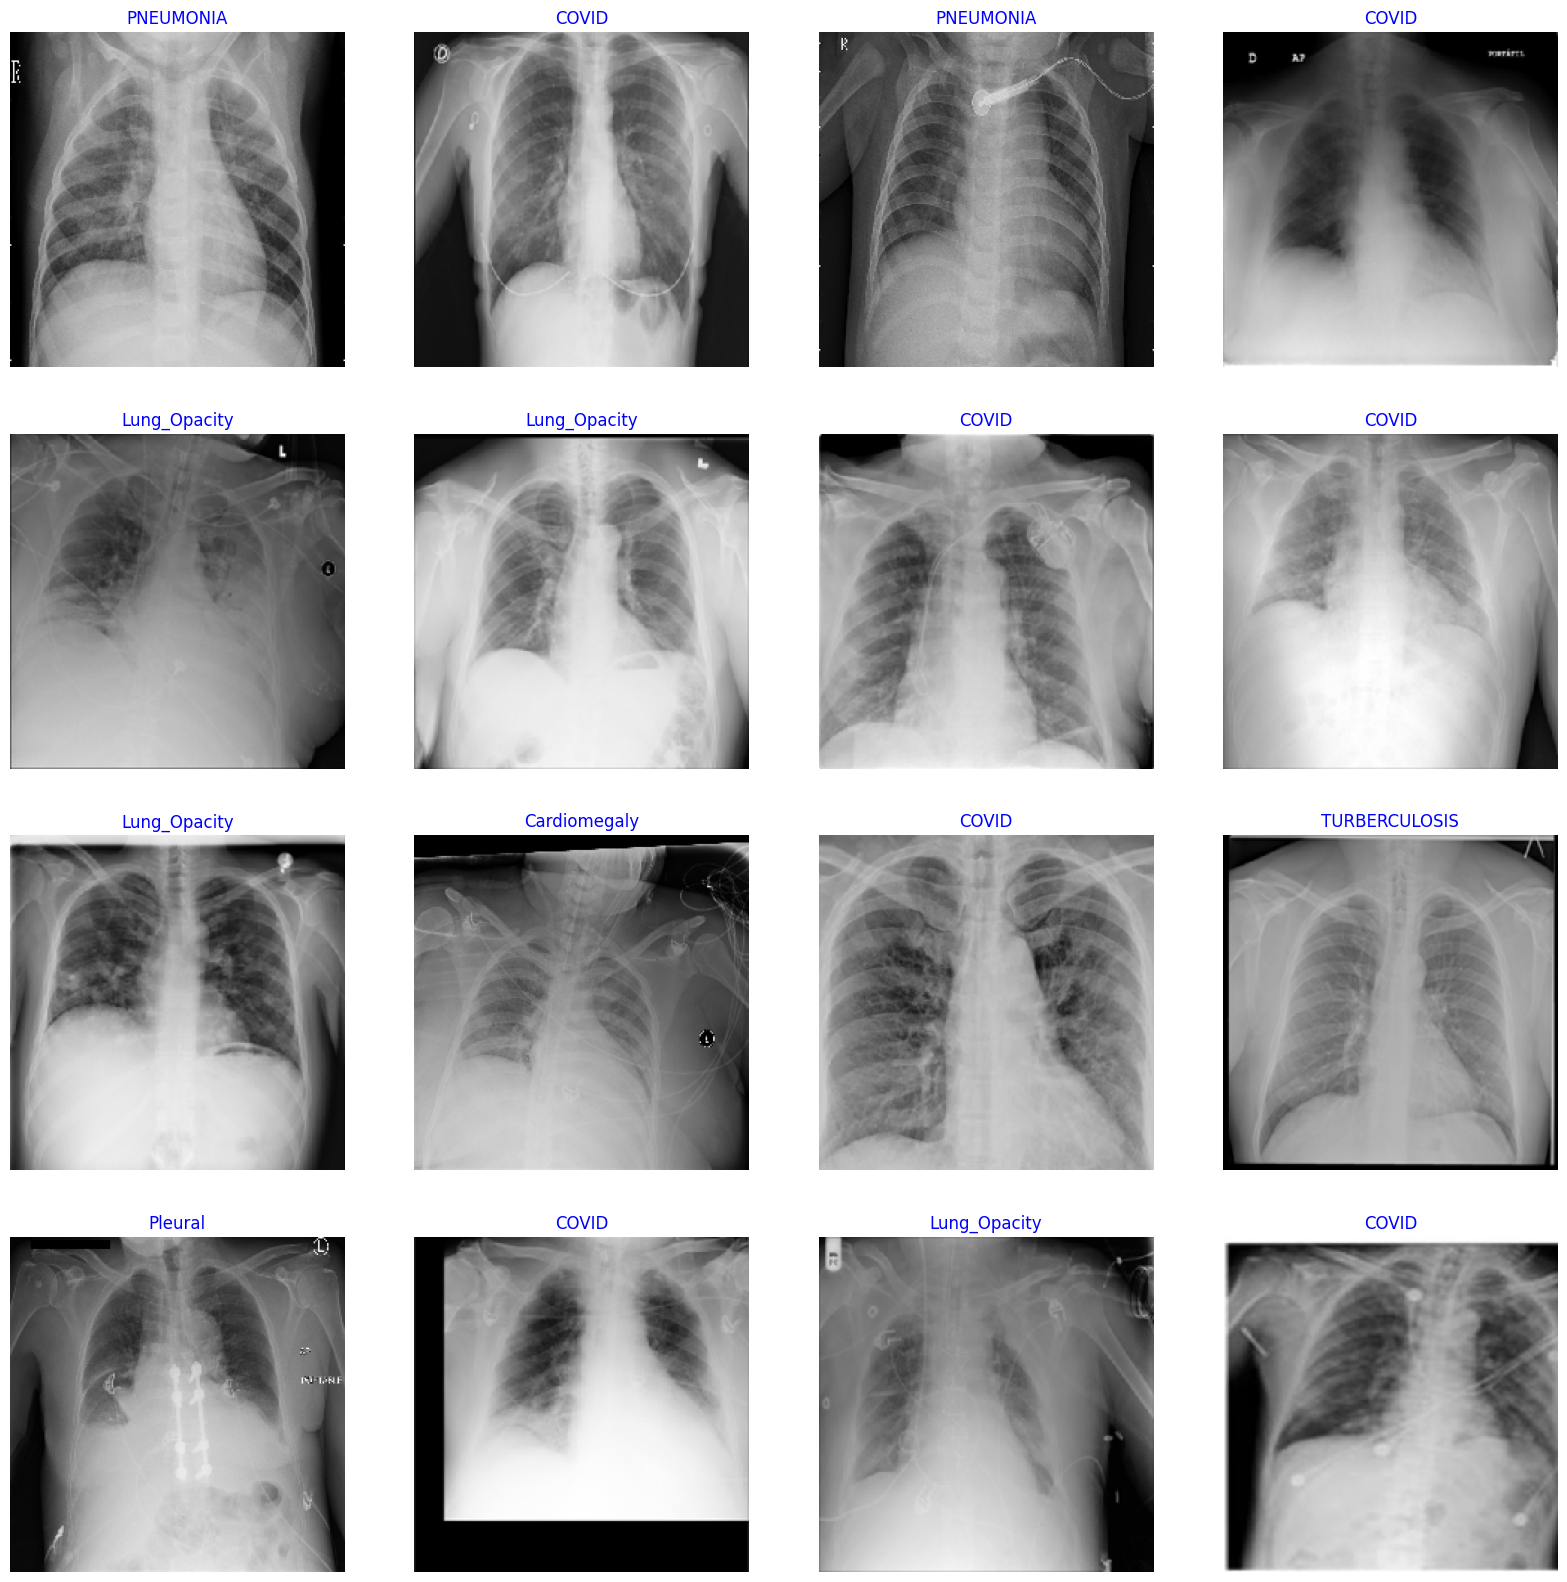

In [41]:
g_dict = train_gen.class_indices      # defines dictionary {'class': index}
classes = list(g_dict.keys())       # defines list of dictionary's kays (classes), classes names : string
images, labels = next(train_gen)      # get a batch size samples from the generator

plt.figure(figsize= (20, 20))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    image = images[i] / 255       # scales data to range (0 - 255)
    plt.imshow(image)
    index = np.argmax(labels[i])  # get image index
    class_name = classes[index]   # get class of image
    plt.title(class_name, color= 'blue', fontsize= 12)
    plt.axis('off')
plt.show()

# Model Structure


In [42]:
# Define image size, channels, and number of classes
img_size = (224, 224)
channels = 3
class_count = len(list(train_gen.class_indices.keys()))

# Load VGG19 pre-trained model
base_model = VGG19(include_top=False, weights='imagenet', input_shape=(img_size[0], img_size[1], channels))
# Freeze the base model's layers
base_model.trainable = False
# Build the model on top of VGG19
model = Sequential([
    base_model,
    Flatten(),
    Reshape((7, 7, 512)),
    Conv2D(256, (2, 2), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    BatchNormalization(axis=-1, momentum=0.99, epsilon=0.001),
    Conv2D(256, (2, 2), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(256, kernel_regularizer=regularizers.l2(l=0.016), 
          activity_regularizer=regularizers.l1(0.006),
          bias_regularizer=regularizers.l1(0.006), activation='relu'),
    Dropout(rate=0.45, seed=123),
    Dense(class_count, activation='softmax'),
])

# Compile the model
model.compile(Adamax(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])

# Print model summary
model.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 vgg19 (Functional)          (None, 7, 7, 512)         20024384  
                                                                 
 flatten_6 (Flatten)         (None, 25088)             0         
                                                                 
 reshape_3 (Reshape)         (None, 7, 7, 512)         0         
                                                                 
 conv2d_6 (Conv2D)           (None, 6, 6, 256)         524544    
                                                                 
 max_pooling2d_6 (MaxPoolin  (None, 3, 3, 256)         0         
 g2D)                                                            
                                                                 
 batch_normalization_6 (Bat  (None, 3, 3, 256)         1024      
 chNormalization)                                     

In [45]:
batch_size = 64   # set batch size for training
epochs = 10   # number of all epochs in training

history = model.fit(x= train_gen, epochs= epochs, verbose= 1, validation_data= valid_gen, 
                    validation_steps= None, shuffle= False)

Epoch 1/10
229/229 [==============================] - 132s 577ms/step - loss: 3.9223 - accuracy: 0.7608 - val_loss: 44.8837 - val_accuracy: 0.8301
Epoch 2/10
229/229 [==============================] - 133s 582ms/step - loss: 2.1465 - accuracy: 0.8687 - val_loss: 26.9562 - val_accuracy: 0.8615
Epoch 3/10
229/229 [==============================] - 132s 576ms/step - loss: 1.2881 - accuracy: 0.9136 - val_loss: 15.4878 - val_accuracy: 0.8825
Epoch 4/10
229/229 [==============================] - 131s 572ms/step - loss: 0.8114 - accuracy: 0.9450 - val_loss: 36.4575 - val_accuracy: 0.8943
Epoch 5/10
229/229 [==============================] - 133s 580ms/step - loss: 0.5335 - accuracy: 0.9725 - val_loss: 26.8565 - val_accuracy: 0.8952
Epoch 6/10
229/229 [==============================] - 131s 571ms/step - loss: 0.3768 - accuracy: 0.9854 - val_loss: 26.1671 - val_accuracy: 0.8970
Epoch 7/10
229/229 [==============================] - 132s 579ms/step - loss: 0.2792 - accuracy: 0.9938 - val_loss: 24

In [46]:
class_names = list(train_gen.class_indices.keys())
print(class_names)


['COVID', 'Cardiomegaly', 'Lung_Opacity', 'NORMAL', 'PNEUMONIA', 'Pleural', 'TURBERCULOSIS']


In [47]:
test_loss, test_accuracy = model.evaluate(test_gen)
print("Test Accuracy:", test_accuracy)


24/24 [==============================] - 18s 490ms/step - loss: 0.4432 - accuracy: 0.9003
Test Accuracy: 0.9002732038497925


# Display model performance¶

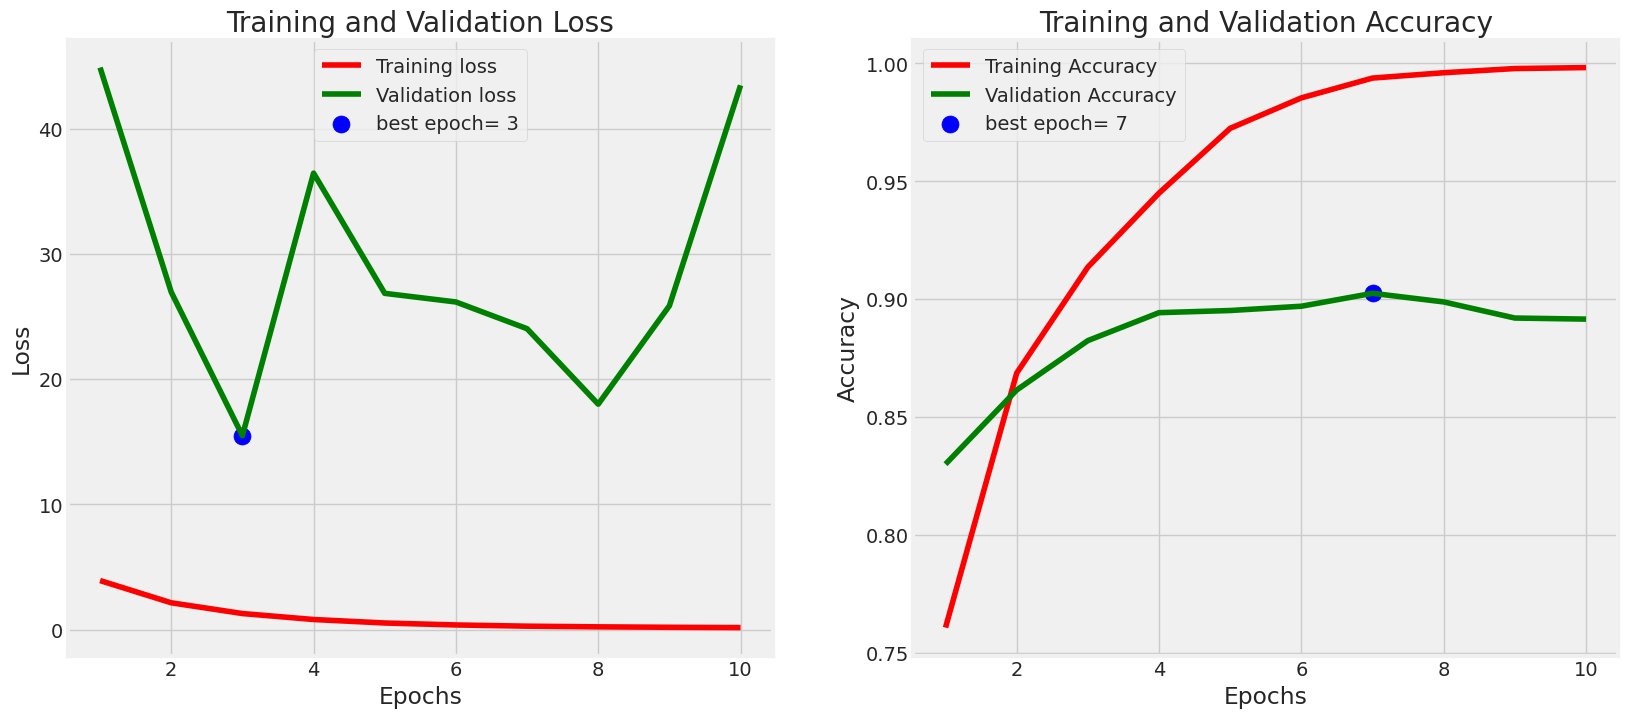

In [48]:
# Define needed variables
tr_acc = history.history['accuracy']
tr_loss = history.history['loss']
val_acc = history.history['val_accuracy']
val_loss = history.history['val_loss']
index_loss = np.argmin(val_loss)
val_lowest = val_loss[index_loss]
index_acc = np.argmax(val_acc)
acc_highest = val_acc[index_acc]
Epochs = [i+1 for i in range(len(tr_acc))]
loss_label = f'best epoch= {str(index_loss + 1)}'
acc_label = f'best epoch= {str(index_acc + 1)}'

# Plot training history
plt.figure(figsize= (20, 8))
plt.style.use('fivethirtyeight')

plt.subplot(1, 2, 1)
plt.plot(Epochs, tr_loss, 'r', label= 'Training loss')
plt.plot(Epochs, val_loss, 'g', label= 'Validation loss')
plt.scatter(index_loss + 1, val_lowest, s= 150, c= 'blue', label= loss_label)
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(Epochs, tr_acc, 'r', label= 'Training Accuracy')
plt.plot(Epochs, val_acc, 'g', label= 'Validation Accuracy')
plt.scatter(index_acc + 1 , acc_highest, s= 150, c= 'blue', label= acc_label)
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout
plt.show()

# Evaluate model

In [49]:
ts_length = len(test_df)
test_batch_size = max(sorted([ts_length // n for n in range(1, ts_length + 1) if ts_length%n == 0 and ts_length/n <= 80]))
test_steps = ts_length // test_batch_size

train_score = model.evaluate(train_gen, steps= test_steps, verbose= 1)
valid_score = model.evaluate(valid_gen, steps= test_steps, verbose= 1)
test_score = model.evaluate(test_gen, steps= test_steps, verbose= 1)

print("Train Loss: ", train_score[0])
print("Train Accuracy: ", train_score[1])
print('-' * 20)
print("Validation Loss: ", valid_score[0])
print("Validation Accuracy: ", valid_score[1])
print('-' * 20)
print("Test Loss: ", test_score[0])
print("Test Accuracy: ", test_score[1])

24/24 [==============================] - 13s 534ms/step - loss: 0.4432 - accuracy: 0.9003
Train Loss:  0.14264662563800812
Train Accuracy:  0.998046875
--------------------
Validation Loss:  0.4481428563594818
Validation Accuracy:  0.8932291865348816
--------------------
Test Loss:  0.4431654214859009
Test Accuracy:  0.9002732038497925


# Get Predictions

In [50]:
preds = model.predict_generator(test_gen)
y_pred = np.argmax(preds, axis=1)

# Confusion Matrics and Classification Report 

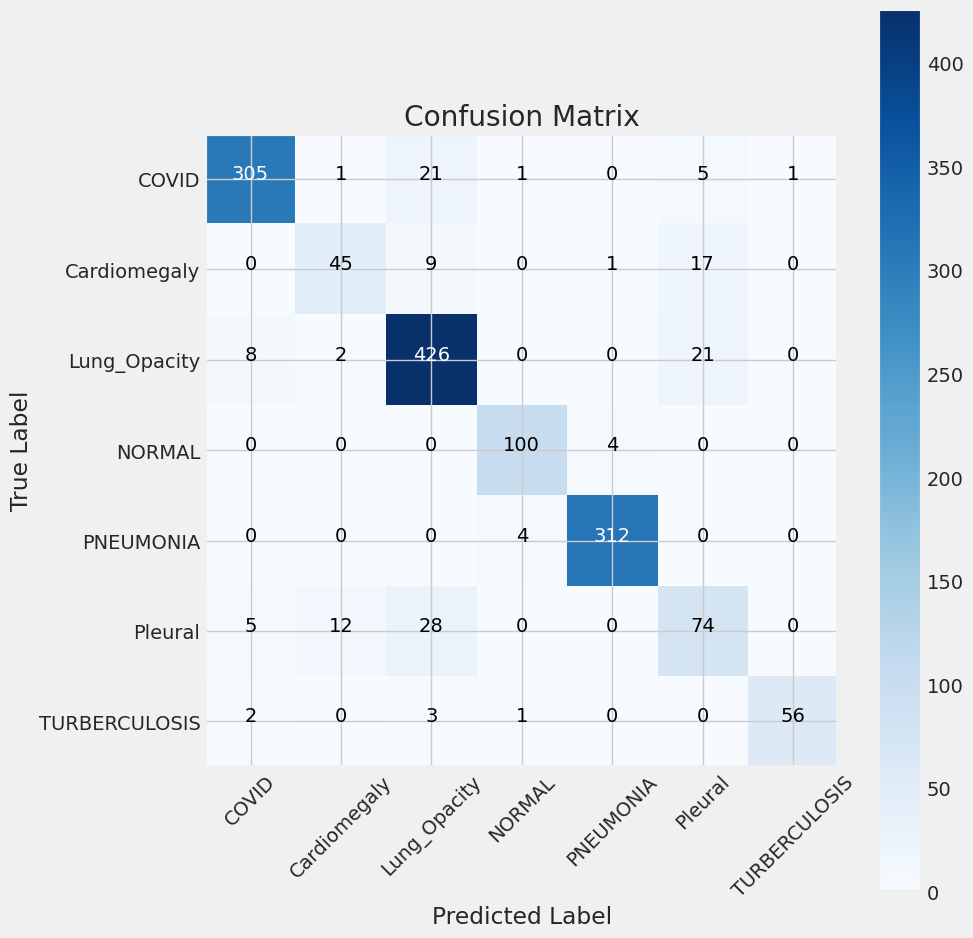

In [51]:
g_dict = test_gen.class_indices
classes = list(g_dict.keys())

# Confusion matrix
cm = confusion_matrix(test_gen.classes, y_pred)

plt.figure(figsize= (10, 10))
plt.imshow(cm, interpolation= 'nearest', cmap= plt.cm.Blues)
plt.title('Confusion Matrix')
plt.colorbar()

tick_marks = np.arange(len(classes))
plt.xticks(tick_marks, classes, rotation= 45)
plt.yticks(tick_marks, classes)


thresh = cm.max() / 2.
for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    plt.text(j, i, cm[i, j], horizontalalignment= 'center', color= 'white' if cm[i, j] > thresh else 'black')

plt.tight_layout()
plt.ylabel('True Label')
plt.xlabel('Predicted Label')

plt.show()


In [52]:
# Classification report
print(classification_report(test_gen.classes, y_pred, target_names= classes))


               precision    recall  f1-score   support

        COVID       0.95      0.91      0.93       334
 Cardiomegaly       0.75      0.62      0.68        72
 Lung_Opacity       0.87      0.93      0.90       457
       NORMAL       0.94      0.96      0.95       104
    PNEUMONIA       0.98      0.99      0.99       316
      Pleural       0.63      0.62      0.63       119
TURBERCULOSIS       0.98      0.90      0.94        62

     accuracy                           0.90      1464
    macro avg       0.87      0.85      0.86      1464
 weighted avg       0.90      0.90      0.90      1464



# **Save model**

In [53]:
model.save('chest_x-raysVGG19+CNN-FINAL.h5')